### 导入相关包

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from utils.model import PINN1
from utils.dataset import get_data

plt.rcParams['axes.unicode_minus'] = False

### 加载模型

In [2]:
# 设置设备
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 加载模型
model = PINN1().to(device)
ckpt_path = 'results/fold_1_best.ckpt'
model.load_state_dict(torch.load(ckpt_path, map_location=device))
model.eval()

PINN1(
  (input1_layer): Sequential(
    (0): Linear(in_features=64, out_features=2048, bias=True)
    (1): LayerNorm((2048,), eps=1e-05, elementwise_affine=True)
    (2): GELU(approximate='none')
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=2048, out_features=1024, bias=True)
    (5): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
    (6): GELU(approximate='none')
    (7): Dropout(p=0.2, inplace=False)
    (8): ResidualBlock(
      (linear1): Linear(in_features=1024, out_features=1024, bias=True)
      (linear2): Linear(in_features=1024, out_features=1024, bias=True)
      (norm1): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
      (activation): GELU(approximate='none')
      (dropout): Dropout(p=0.2, inplace=False)
      (shortcut): Identity()
    )
    (9): ResidualBlock(
      (linear1): Linear(in_features=1024, out_features=1024, bias=True)
      (linear2): Linear(in_featu

### 随机抽取测试集

In [3]:
# 读取数据
data_dir = 'data/model2/'
x1, x2, y = get_data(data_dir, device)

# 随机抽取10个样本
num_samples = x1.shape[0]
indices = np.random.choice(num_samples, 10, replace=False)
x1_sample = x1[indices]
x2_sample = x2[indices]
y_true_sample = y[indices]

torch.Size([16000, 64]) torch.Size([16000, 125, 3]) torch.Size([16000, 8, 125])


In [4]:
x1_sample

tensor([[3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
         3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
         3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
         3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
         3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
         3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
         3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000, 3.0000,
         3.0000],
        [2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
         2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
         2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
         2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
         2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000, 2.0000,
         2

In [5]:
# 预测
def predict(model, x1, x2):
    # 单个样本预测，去掉批量维度
    X_arr = x2[:, 0]  # [125]
    Y_arr = x2[:, 1]  # [125]
    Z_arr = x2[:, 2]  # [125]
    X_tr = X_arr.unsqueeze(0).to(device)  # [1, 125]
    Y_tr = Y_arr.unsqueeze(0).to(device)  # [1, 125]
    Z_tr = Z_arr.unsqueeze(0).to(device)  # [1, 125]
    X_tr.requires_grad_(True)
    Y_tr.requires_grad_(True)
    Z_tr.requires_grad_(True)
    with torch.no_grad():
        y_pred = model(x1.unsqueeze(0), X_tr, Y_tr, Z_tr)  # x1也要增加批量维度
        y_pred = y_pred.view(8, 125)  # 单个样本输出形状 [8, 125]
    return y_pred

# 逐个预测每个样本
y_pred_sample = []
for i in range(10):
    y_pred = predict(model, x1_sample[i], x2_sample[i])
    y_pred_sample.append(y_pred)
y_pred_sample = torch.stack(y_pred_sample)  # [10, 8, 125]

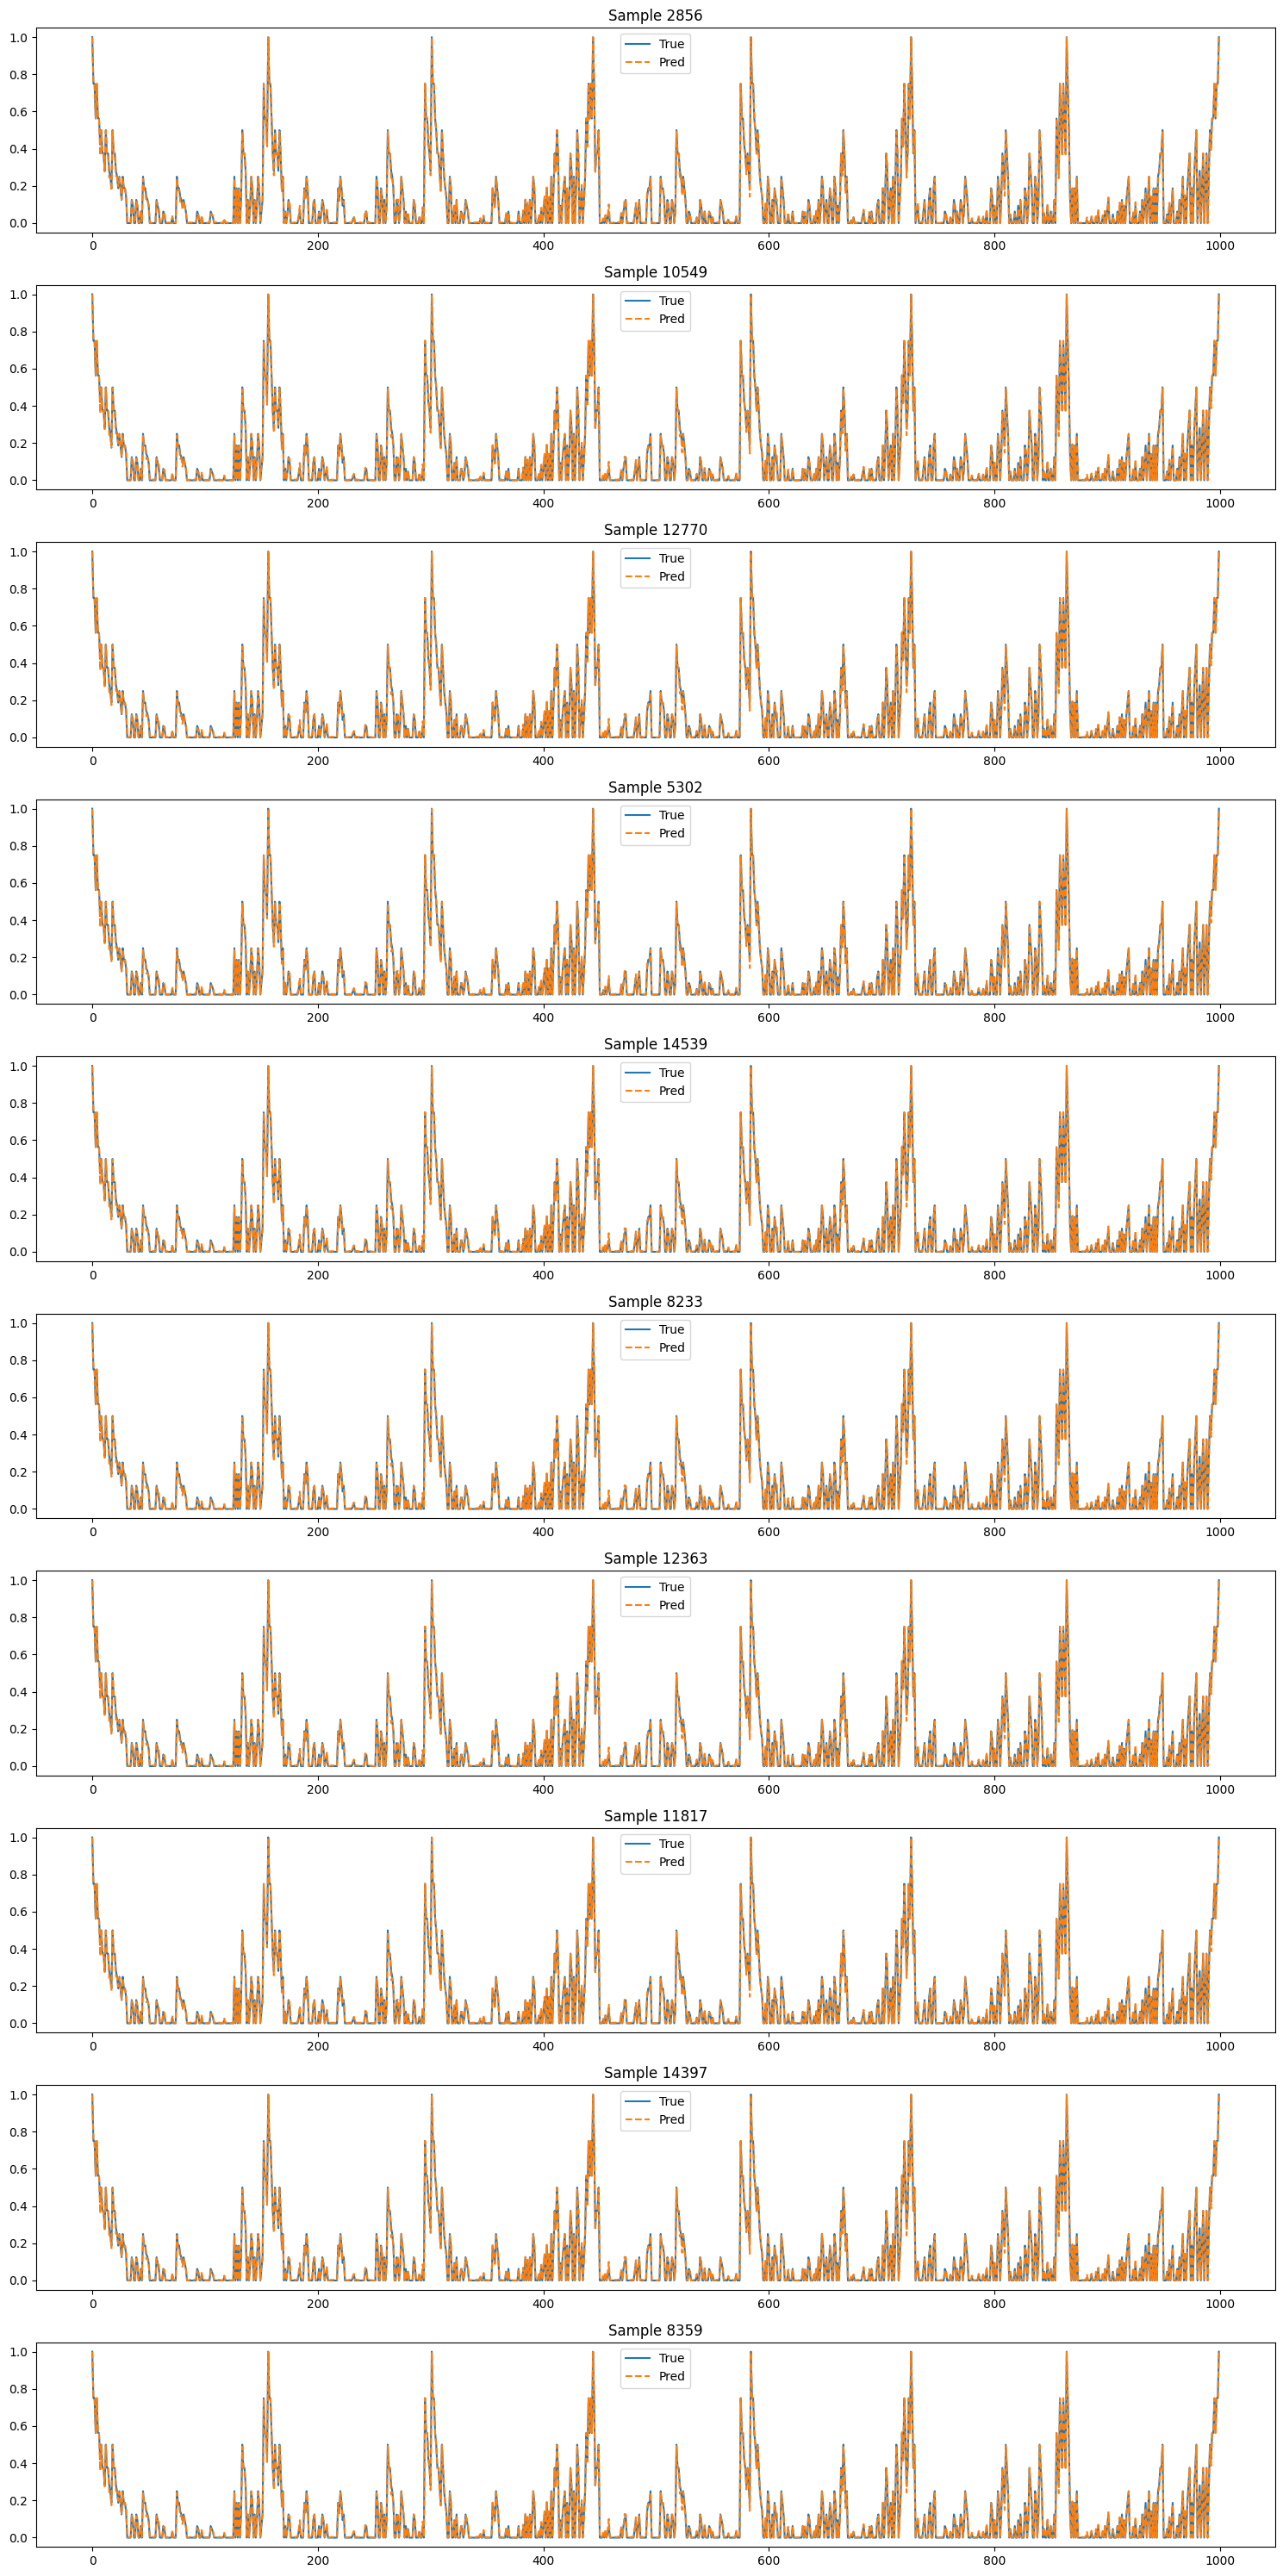

In [6]:
# 绘制结果
fig, axes = plt.subplots(10, 1, figsize=(15, 30))
for i in range(10):
    axes[i].plot(y_true_sample[i].cpu().numpy().flatten(), label='True')
    axes[i].plot(y_pred_sample[i].cpu().numpy().flatten(), label='Pred', linestyle='--')
    axes[i].set_title(f'Sample {indices[i]}')
    axes[i].legend()
plt.tight_layout()
plt.show()

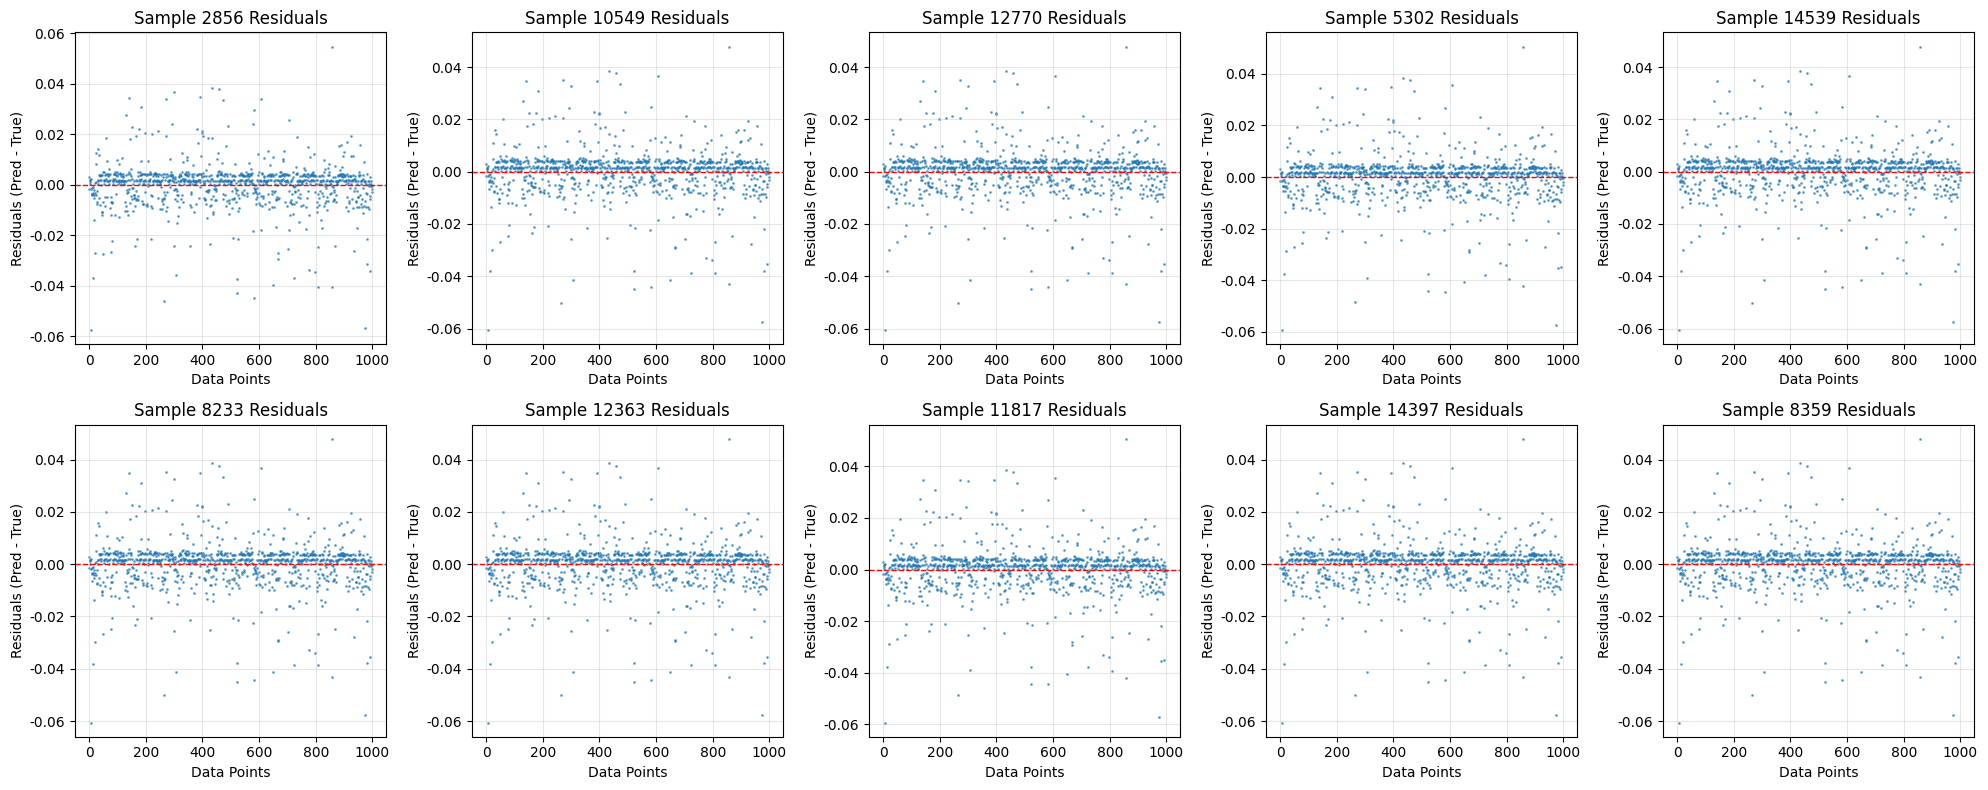

残差统计信息:
Sample 2856: MAE=0.005736, MSE=0.000089, RMSE=0.009441
Sample 10549: MAE=0.005800, MSE=0.000092, RMSE=0.009566
Sample 12770: MAE=0.005800, MSE=0.000092, RMSE=0.009566
Sample 5302: MAE=0.005776, MSE=0.000090, RMSE=0.009510
Sample 14539: MAE=0.005800, MSE=0.000092, RMSE=0.009566
Sample 8233: MAE=0.005800, MSE=0.000092, RMSE=0.009566
Sample 12363: MAE=0.005800, MSE=0.000092, RMSE=0.009566
Sample 11817: MAE=0.005776, MSE=0.000090, RMSE=0.009510
Sample 14397: MAE=0.005800, MSE=0.000092, RMSE=0.009566
Sample 8359: MAE=0.005800, MSE=0.000092, RMSE=0.009566


In [8]:
# 计算残差
residuals = y_pred_sample - y_true_sample

# 绘制残差图
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i in range(10):
    # 绘制残差散点图
    residual_flat = residuals[i].cpu().numpy().flatten()
    points = np.arange(len(residual_flat))  # 数据点索引
    
    axes[i].scatter(points, residual_flat, alpha=0.6, s=1)
    axes[i].axhline(y=0, color='red', linestyle='--', linewidth=1)
    axes[i].set_xlabel('Data Points')
    axes[i].set_ylabel('Residuals (Pred - True)')
    axes[i].set_title(f'Sample {indices[i]} Residuals')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# 计算并显示残差统计信息
print("残差统计信息:")
for i in range(10):
    residual_flat = residuals[i].cpu().numpy().flatten()
    mae = np.mean(np.abs(residual_flat))
    mse = np.mean(residual_flat**2)
    rmse = np.sqrt(mse)
    print(f"Sample {indices[i]}: MAE={mae:.6f}, MSE={mse:.6f}, RMSE={rmse:.6f}")

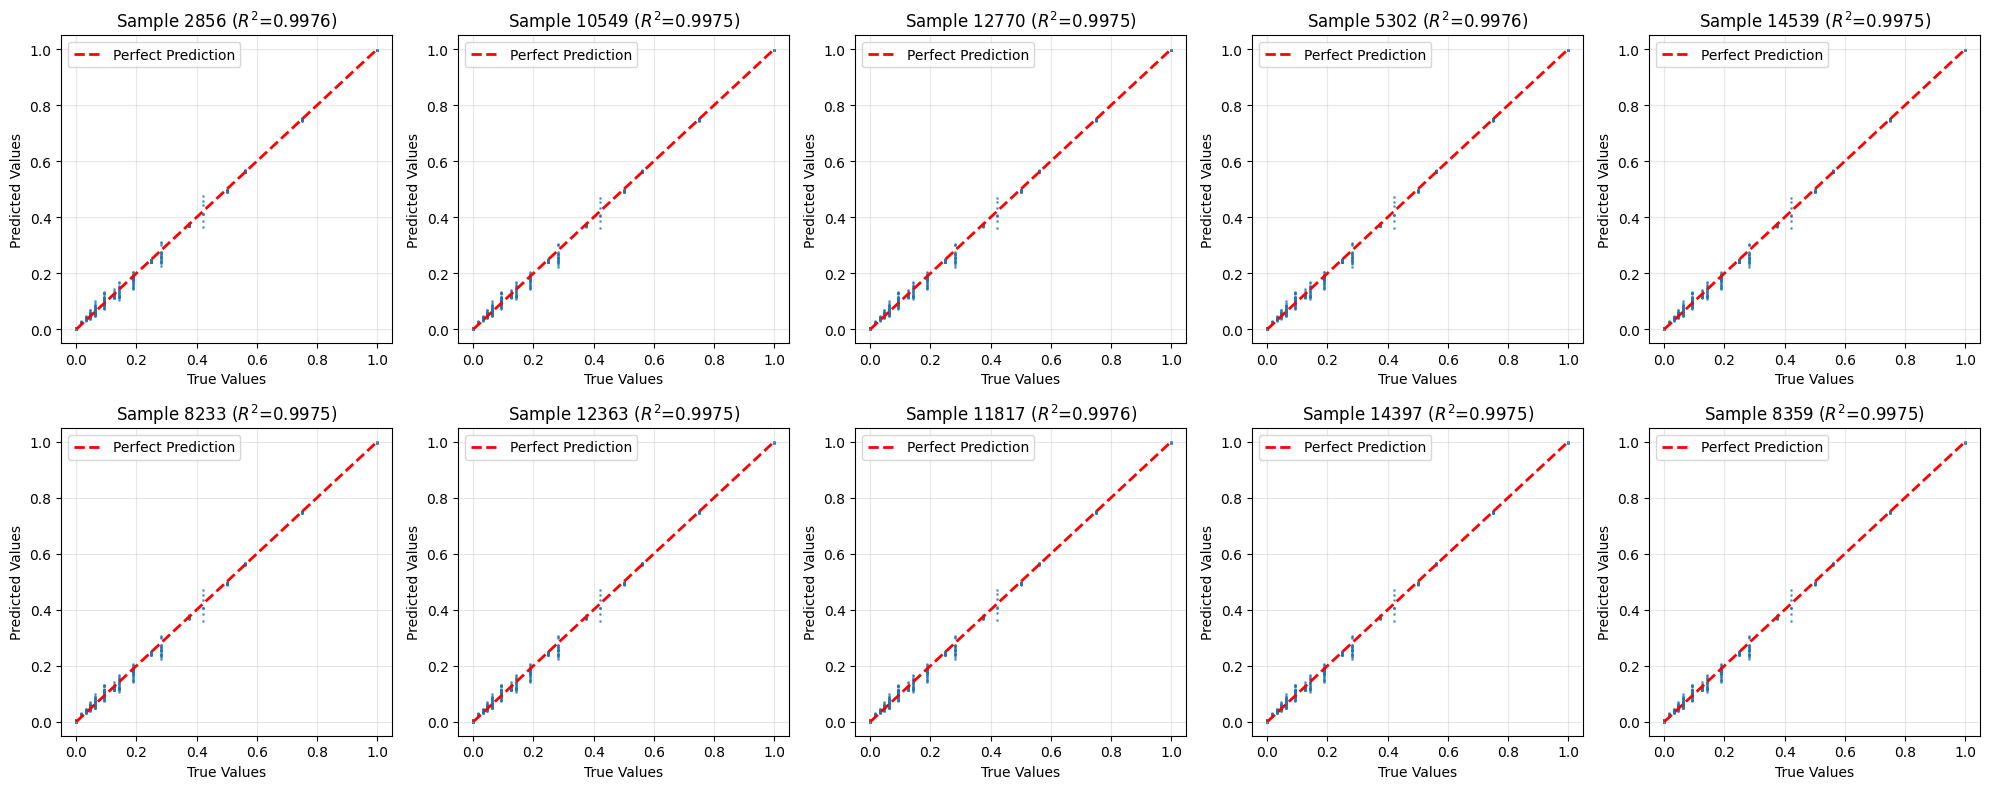

Font 'default' does not have a glyph for '\u5206' [U+5206], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u6570' [U+6570], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u5e03' [U+5e03], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u5206' [U+5206], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u6570' [U+6570], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u5e03' [U+5e03], substituting with a dummy symbol.


R²统计信息:
Sample 2856: R² = 0.997598
Sample 10549: R² = 0.997534
Sample 12770: R² = 0.997534
Sample 5302: R² = 0.997563
Sample 14539: R² = 0.997534
Sample 8233: R² = 0.997534
Sample 12363: R² = 0.997534
Sample 11817: R² = 0.997563
Sample 14397: R² = 0.997534
Sample 8359: R² = 0.997534

平均R²: 0.997546
R²标准差: 0.000021
最小R²: 0.997534
最大R²: 0.997598


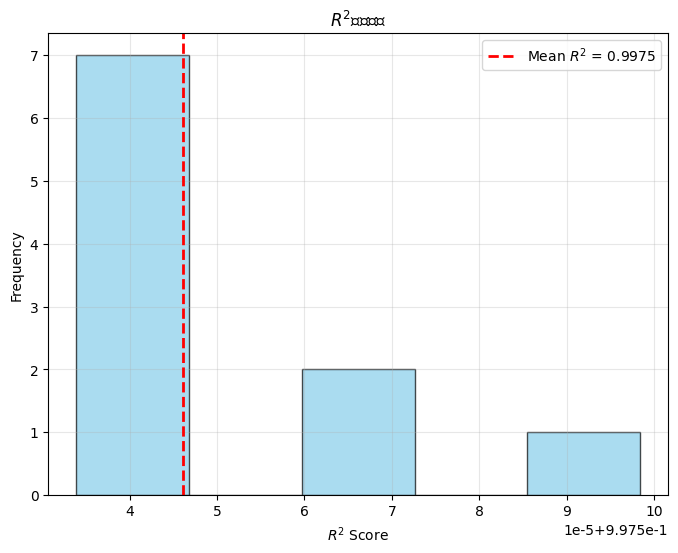

In [9]:
# 绘制R²散点图（真实值 vs 预测值）
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

r2_scores = []
for i in range(10):
    true_flat = y_true_sample[i].cpu().numpy().flatten()
    pred_flat = y_pred_sample[i].cpu().numpy().flatten()
    
    # 计算R²值
    r2 = r2_score(true_flat, pred_flat)
    r2_scores.append(r2)
    
    # 绘制真实值 vs 预测值散点图
    axes[i].scatter(true_flat, pred_flat, alpha=0.6, s=1)
    
    # 绘制理想预测线 y=x
    min_val = min(true_flat.min(), pred_flat.min())
    max_val = max(true_flat.max(), pred_flat.max())
    axes[i].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect Prediction')
    
    axes[i].set_xlabel('True Values')
    axes[i].set_ylabel('Predicted Values')
    axes[i].set_title(f'Sample {indices[i]} ($R^2$={r2:.4f})')
    axes[i].grid(True, alpha=0.3)
    axes[i].legend()

plt.tight_layout()
plt.show()

# 显示R²统计信息
print("R²统计信息:")
for i in range(10):
    print(f"Sample {indices[i]}: R² = {r2_scores[i]:.6f}")

print(f"\n平均R²: {np.mean(r2_scores):.6f}")
print(f"R²标准差: {np.std(r2_scores):.6f}")
print(f"最小R²: {np.min(r2_scores):.6f}")
print(f"最大R²: {np.max(r2_scores):.6f}")

# 绘制R²分布直方图
plt.figure(figsize=(8, 6))
plt.hist(r2_scores, bins=5, alpha=0.7, color='skyblue', edgecolor='black')
plt.xlabel('$R^2$ Score')
plt.ylabel('Frequency')
plt.title('$R^2$分数分布')
plt.grid(True, alpha=0.3)
plt.axvline(np.mean(r2_scores), color='red', linestyle='--', linewidth=2, label=f'Mean $R^2$ = {np.mean(r2_scores):.4f}')
plt.legend()
plt.show()